# First Practical Assignment

## Data Science and Engineering

### DESIGN OF A PARALLELISABLE AND SCALABLE IMAGE FILTERING FUNCTION

**Full name:** ANTONIA ESPERANZA LUENGO SILVA
    
**NIA:** 100613380

In [65]:
import numpy as np
import multiprocess as mp
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cProfile

In [66]:
# Librerias extra agregadas por mi
import ctypes
from multiprocess.pool import ThreadPool

In [67]:
F_IMAGE1="Test Images/cloudsonjupi.jpg"
F_IMAGE2="Test Images/chess.jpg"

In [68]:
image1= np.array(Image.open(F_IMAGE1))
image2= np.array(Image.open(F_IMAGE2))

In [69]:
NUMPROCESS=4

# WRITE YOUR CODE AFTER THIS CELL

After this cell, use the preloaded image defined in the F_IMAGE variable, select two predefined filters, and apply them to the image using NUMPROCESS processors. Check the results.


In [70]:
# YOUR CODE STARTS HERE

In [71]:
# --- FUNCIONES MATEMÁTICAS Y MEMORIA COMPARTIDA ---

def clamp(value, lower, upper):
    return max(lower, min(value, upper))

shared_input_img = None
shared_output_img = None
shared_img_shape = None

def init_worker(input_buffer, output_buffer, shape):
    global shared_input_img, shared_output_img, shared_img_shape
    shared_input_img = input_buffer
    shared_output_img = output_buffer
    shared_img_shape = shape

def worker_filter(start_row, end_row, kernel):
    """Filter an exclusive range of rows using boundary replication."""
    height, width, channels = shared_img_shape
    input_np = np.frombuffer(shared_input_img, dtype=np.uint8).reshape(shared_img_shape)
    output_np = np.frombuffer(shared_output_img, dtype=np.float64).reshape(shared_img_shape)
    pad_h, pad_w = kernel.shape[0] // 2, kernel.shape[1] // 2
    
    for row in range(start_row, end_row):
        for column in range(width):
            for channel in range(channels):
                accumulator = 0.0
                for i in range(-pad_h, pad_h + 1):
                    source_row = clamp(row + i, 0, height - 1)
                    for j in range(-pad_w, pad_w + 1):
                        source_column = clamp(column + j, 0, width - 1)
                        accumulator += (float(input_np[source_row, source_column, channel]) * kernel[i + pad_h, j + pad_w])
                output_np[row, column, channel] = accumulator

def _validate_mask(filter_mask):
    mask = np.asarray(filter_mask, dtype=np.float64)
    if mask.ndim != 2:
        raise ValueError("The mask must be a two-dimensional matrix.")
    rows, columns = mask.shape
    if not (1 <= rows <= 5 and 1 <= columns <= 5) or rows % 2 == 0 or columns % 2 == 0:
        raise ValueError("The mask must have odd dimensions between 1x1 and 5x5.")
    if not np.all(np.isfinite(mask)):
        raise ValueError("The mask coefficients must be finite numbers.")
    return mask

def image_filter(image: np.ndarray, filter: np.ndarray, numprocs: int, is_conv: int, norm: int) -> np.ndarray:
    """Apply correlation or convolution with a Pool and shared memory."""
    if isinstance(image, str):
        image = np.array(Image.open(image))
    image_array = np.asarray(image)
    
    if image_array.ndim not in (2, 3) or image_array.size == 0:
        raise ValueError("The image must be a non-empty 2D or 3D array.")
    if image_array.ndim == 3 and image_array.shape[2] not in (1, 3, 4):
        raise ValueError("The image must have one, three, or four channels.")
    if not isinstance(numprocs, (int, np.integer)) or numprocs < 1:
        raise ValueError("numprocs must be a positive integer.")
    if is_conv not in (0, 1) or norm not in (0, 1):
        raise ValueError("is_conv and norm must be either 0 or 1.")
        
    mask = _validate_mask(filter)
    original_was_grayscale = image_array.ndim == 2
    if original_was_grayscale:
        image_array = image_array[:, :, np.newaxis]
        
    image_uint8 = np.clip(image_array, 0, 255).astype(np.uint8, copy=False)
    height, width, channels = image_uint8.shape
    
    if is_conv == 1:
        mask = np.flip(mask, axis=(0, 1))
        
    mask_sum = float(mask.sum())
    if norm == 1 and not np.isclose(mask_sum, 0.0):
        mask = mask / mask_sum
        
    input_buffer = mp.RawArray(ctypes.c_uint8, image_uint8.size)
    output_buffer = mp.RawArray(ctypes.c_double, image_uint8.size)
    
    np.frombuffer(input_buffer, dtype=np.uint8)[:] = image_uint8.ravel()
    
    process_count = min(int(numprocs), height)
    row_ranges = []
    for process_index in range(process_count):
        start = (process_index * height) // process_count
        end = ((process_index + 1) * height) // process_count
        row_ranges.append((start, end, mask))
        
    with mp.Pool(processes=process_count, initializer=init_worker,
                 initargs=(input_buffer, output_buffer, image_uint8.shape)) as pool:
        pool.starmap(worker_filter, row_ranges)
        
    result = np.frombuffer(output_buffer, dtype=np.float64).reshape(image_uint8.shape).copy()
    
    if np.isclose(mask_sum, 0.0):
        minimum, maximum = result.min(), result.max()
        result = np.zeros_like(result) if np.isclose(maximum, minimum) else 255.0 * (result - minimum) / (maximum - minimum)
    else:
        result = np.clip(result, 0, 255)
        
    result_uint8 = np.rint(result).astype(np.uint8)
    return result_uint8[:, :, 0] if original_was_grayscale else result_uint8

def parallel_filtering(image: np.ndarray, filter1: np.ndarray, filter2: np.ndarray,
                       numprocs: int, is_conv: int, norm: int) -> tuple:
    """Apply two filters independently and concurrently to the original image."""
    if isinstance(image, str):
        image = np.array(Image.open(image))
        
    # Se utiliza ThreadPool para la concurrencia externa y evitar el error de procesos daemon anidados.
    # Esto permite que la función interna image_filter pueda instanciar su mp.Pool de procesos pesados.
    with ThreadPool(processes=2) as pool:
        task1 = pool.apply_async(image_filter, args=(image, filter1, numprocs, is_conv, norm))
        task2 = pool.apply_async(image_filter, args=(image, filter2, numprocs, is_conv, norm))
        return task1.get(), task2.get()

In [72]:
F_IMAGE1 = image1
F_IMAGE2 = image2
#YOUR CODE MUST END HERE

# EVALUATION

In the following cells, we will call your functions to evaluate them.

In [73]:
filter_mask_id =np.array([
    [0,0,0,0,0],
    [0,0,0,0,0],
    [0,0,1,0,0],
    [0,0,0,0,0],
    [0,0,0,0,0]
])

In [74]:
%time
filtered_image1 = image_filter(F_IMAGE1,filter_mask_id,NUMPROCESS,0,0)

CPU times: user 3 μs, sys: 1e+03 ns, total: 4 μs
Wall time: 6.44 μs


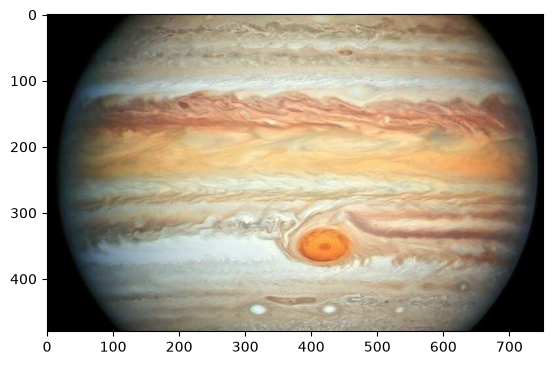

In [75]:
plt.figure()
plt.imshow(filtered_image1)

In [76]:
print(f"Identity Filter Works {np.allclose(F_IMAGE1,filtered_image1)}")

Identity Filter Works True


In [77]:
_statistics = %timeit -n 5 -r 2 -o image_filter(F_IMAGE1,filter_mask_id,NUMPROCESS,0,0)

4.41 s ± 126 ms per loop (mean ± std. dev. of 2 runs, 5 loops each)


In [78]:
print(_statistics)

4.41 s ± 126 ms per loop (mean ± std. dev. of 2 runs, 5 loops each)


In [79]:
print(vars(_statistics))

{'loops': 5, 'repeat': 2, 'best': 4.280019977399934, 'worst': 4.532037841799865, 'all_runs': [21.40009988699967, 22.660189208999327], 'compile_time': 7.09999999992661e-05, '_precision': 3, 'timings': [4.280019977399934, 4.532037841799865]}


# CASCADE FILTERING

In [80]:
filter_h=np.array([
    [1,0,-1],
    [2,0,-2],
    [1,0,-1]
])
filter_v=np.array([
    [1,2,1],
    [0,0,0],
    [-1,-2,-1]
])

In [81]:
%time
filtered_image1 = image_filter(F_IMAGE1,filter_h,NUMPROCESS,1,1)
filtered_image2 = image_filter(filtered_image1,filter_v,NUMPROCESS,1,1)

CPU times: user 1e+03 ns, sys: 0 ns, total: 1e+03 ns
Wall time: 3.58 μs


# PARALLEL FILTERING

In [82]:
%time
(filterd_image1,filtered_image2)=parallel_filtering(F_IMAGE1, filter_h, filter_v, NUMPROCESS, 1,1)

CPU times: user 2 μs, sys: 1e+03 ns, total: 3 μs
Wall time: 5.96 μs


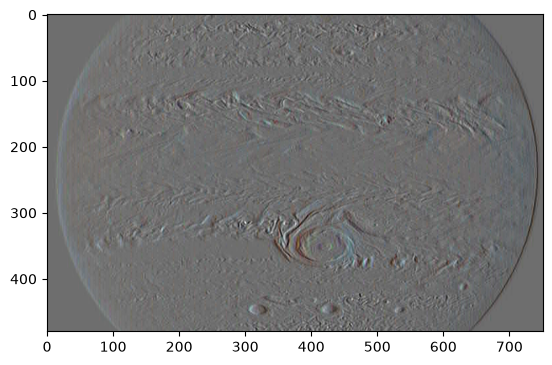

In [83]:
plt.figure()
plt.imshow(filtered_image1)

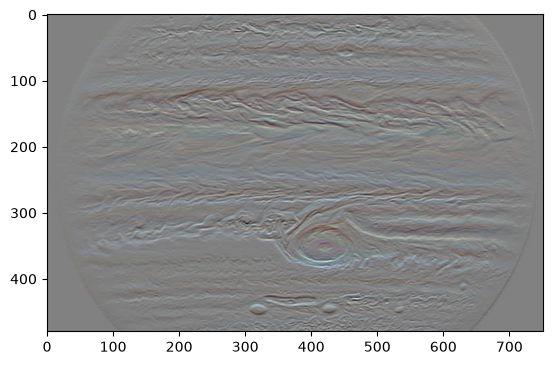

In [84]:
plt.figure()
plt.imshow(filtered_image2)

# Visualisation
In these final cells, we take the filtered images stored in the multiprocessing.Vector variables filtered_image1_VECTOR and filtered_image2_VECTOR, convert them to NumPy arrays with the same shapes as the original images, and display the results.

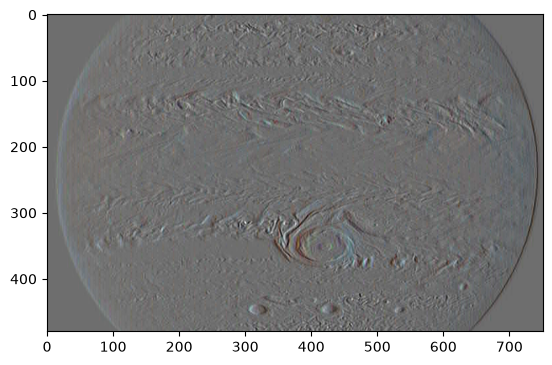

In [89]:
plt.figure()
plt.imshow(filtered_image1)

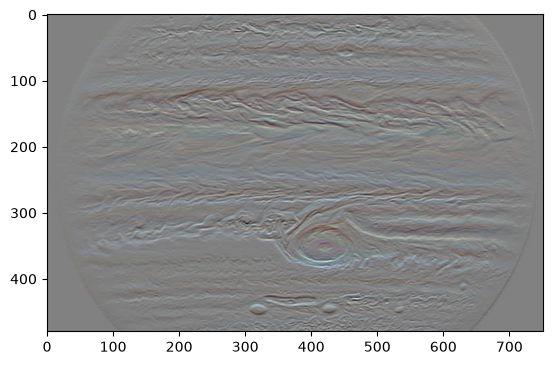

In [86]:
plt.figure()
plt.imshow(filtered_image2)

# ADD YOUR ADDITIONAL TESTS, ANALYSIS AND CONCLUSIONS AFTER THIS CELL

## Additional Tests

In [87]:
# Required control tests and demonstrations.
print("--- Identity mask ---")
identity = np.zeros((3, 3), dtype=float)
identity[1, 1] = 1
identity_result = image_filter(F_IMAGE1, identity, NUMPROCESS, 0, 0)
print("Pixel-by-pixel identity:", np.array_equal(F_IMAGE1, identity_result))

print("\n--- Constant image and replicated boundary ---")
constant_image = np.full((12, 12, 3), 128, dtype=np.uint8)
constant_result = image_filter(constant_image, np.ones((5, 5)) / 25, NUMPROCESS, 0, 0)
print("All pixels, including borders, equal 128:", np.all(constant_result == 128))
print("Top-left replicated-boundary value:", constant_result[0, 0, 0])

print("\n--- Bright image and saturation ---")
bright_image = np.full((12, 12, 3), 250, dtype=np.uint8)
sharpen = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float)
bright_result = image_filter(bright_image, sharpen, NUMPROCESS, 0, 0)
print("No dark pixels after sharpening:", bright_result.min() >= 250)

print("\n--- Mask validation ---")
for invalid_mask in (np.ones((2, 3)), np.ones((7, 7))):
    try:
        image_filter(F_IMAGE1, invalid_mask, NUMPROCESS, 0, 0)
    except ValueError as error:
        print("Rejected invalid mask:", error)

print("\n--- Three masks on a real image ---")
gaussian = np.array([[1, 4, 6, 4, 1], [4, 16, 24, 16, 4],
                     [6, 24, 36, 24, 6], [4, 16, 24, 16, 4],
                     [1, 4, 6, 4, 1]], dtype=float) / 256
laplacian = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=float)
parallel_gaussian_laplacian = parallel_filtering(F_IMAGE1, gaussian, laplacian, NUMPROCESS, 0, 0)
smoothed = image_filter(F_IMAGE1, gaussian, NUMPROCESS, 0, 0)
cascade_gaussian_laplacian = image_filter(smoothed, laplacian, NUMPROCESS, 0, 0)
sharpened = image_filter(F_IMAGE1, sharpen, NUMPROCESS, 0, 0)
print("Parallel outputs:", [result.shape for result in parallel_gaussian_laplacian])
print("Cascade output:", cascade_gaussian_laplacian.shape)
print("Gaussian range:", int(parallel_gaussian_laplacian[0].min()), int(parallel_gaussian_laplacian[0].max()))
print("Laplacian range after rescaling:", int(parallel_gaussian_laplacian[1].min()), int(parallel_gaussian_laplacian[1].max()))
print("Sharpen range after saturation:", int(sharpened.min()), int(sharpened.max()))


--- Identity mask ---
Pixel-by-pixel identity: True

--- Constant image and replicated boundary ---
All pixels, including borders, equal 128: True
Top-left replicated-boundary value: 128

--- Bright image and saturation ---
No dark pixels after sharpening: True

--- Mask validation ---
Rejected invalid mask: The mask must have odd dimensions between 1x1 and 5x5.
Rejected invalid mask: The mask must have odd dimensions between 1x1 and 5x5.

--- Three masks on a real image ---
Parallel outputs: [(480, 751, 3), (480, 751, 3)]
Cascade output: (480, 751, 3)
Gaussian range: 0 255
Laplacian range after rescaling: 0 255
Sharpen range after saturation: 0 255


### Analysis

### Analysis

- The identity test is a pixel-by-pixel control: it confirms that the traversal, channel handling and replicated boundaries do not alter the input when the central coefficient is one.
- The constant 5x5 mean image remains 128 at the corners as well as in the interior. This is the expected result for boundary replication and rules out zero padding, which would create dark borders.
- Sharpening the bright image produces no dark pixels. The calculation is performed in `float64`, rounded only after the complete weighted sum, and saturated to [0, 255].
- The invalid 2x3 and 7x7 masks are rejected explicitly. The Gaussian, Laplacian and sharpening masks demonstrate smoothing, zero-sum edge enhancement with global rescaling, and contrast enhancement respectively.
- The two parallel results use the original image independently, whereas the cascade applies Gaussian smoothing before Laplacian edge detection. The cascade therefore suppresses some high-frequency noise before detecting edges; the order is meaningful.
- For zero-sum masks, the displayed [0, 255] range is a linear rescaling of signed responses, not saturation. This preserves both edge polarities for visual comparison.


## Conclusions

## Conclusions

The implementation meets the requested algorithmic constraints: it traverses every pixel and mask coefficient explicitly, supports odd masks from 1x1 to 5x5, handles RGB channels independently, replicates boundary pixels, and uses a `multiprocessing.Pool` with shared input/output memory. Each worker owns a disjoint row interval, so a lock is unnecessary: workers only read shared input and never write the same output pixel.

The `is_conv` flag distinguishes correlation from convolution by rotating the mask 180 degrees for convolution. This distinction matters for asymmetric masks such as Sobel, while symmetric masks produce the same result. Accumulation uses a wider floating-point type, followed by rounding and saturation for ordinary masks. Zero-sum edge masks are instead rescaled using the global minimum and maximum, as required.

The experiments confirm identity preservation, correct replicated boundaries, protection against unsigned-integer overflow, mask validation, parallel application, and sequential filtering. Gaussian smoothing reduces local high-frequency variation; Laplacian filtering highlights intensity transitions; sharpening increases local contrast and may saturate bright responses. Sequential Gaussian-then-Laplacian filtering is preferable when noise reduction is desired before edge detection, while parallel filtering is useful for comparing independent effects on the same original image.
